# PROYEK ANALITIKA DATA: Prediksi Telco Customer Churn
**Nama:** Adelia Rahmawati
**NIM:** F12.2024.00154

---

## SOAL 01: Menentukan Tujuan dan Kebutuhan Pemodelan

**a. Masalah bisnis**
* **Masalah:** pelanggan telco banyak yang berhenti berlangganan (*churn*), jadi pendapatan perusahaan ikut turun.
* **Stakeholder:** Tim Marketing dan Tim Retensi Pelanggan.
* **Keputusan yang didukung:** siapa saja yang perlu dikasih promo retensi, supaya anggaran promo tepat sasaran dan nggak terbuang ke pelanggan yang memang sudah loyal.

**b. Business objective:** menurunkan *churn rate* sebesar 5% pada kuartal berikutnya.

**c. Analytical objective:** membangun model klasifikasi untuk memprediksi pelanggan mana yang berisiko *churn* bulan depan.
* **Pertanyaan analitik:** fitur apa yang paling berpengaruh ke keputusan pelanggan berhenti (lama langganan, tagihan bulanan, jenis layanan)?
* **Info yang dibutuhkan dari dataset:** profil pelanggan, layanan yang dipakai, jenis kontrak, tagihan, dan label `Churn`.

In [1]:
import pandas as pd

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# hitung churn rate awal
jumlah_churn = (df['Churn'] == 'Yes').sum()
churn_rate = jumlah_churn / len(df) * 100

print("Total pelanggan:", len(df))
print("Jumlah churn:", jumlah_churn)
print(f"Churn rate: {churn_rate:.2f}%")

Total pelanggan: 7043
Jumlah churn: 1869
Churn rate: 26.54%


**Insight:** *churn rate* saat ini **26,54%** (1.869 dari 7.043 pelanggan), artinya lebih dari seperempat pelanggan pergi. Angka ini tinggi, jadi tujuan menurunkan churn memang relevan.

Catatan penting: datanya **tidak seimbang** (±74% bertahan vs ±26% churn). Ini bakal kita ingat terus sampai tahap evaluasi.

## SOAL 02: Menelaah, Memvalidasi, dan Menyiapkan Data

### 2a. Menelaah Karakteristik Data
Kita cek dulu struktur data (7.043 baris, 21 kolom), statistik deskriptif, lalu bikin bar plot untuk lihat hubungan `tenure` dan `MonthlyCharges` dengan `Churn`.

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


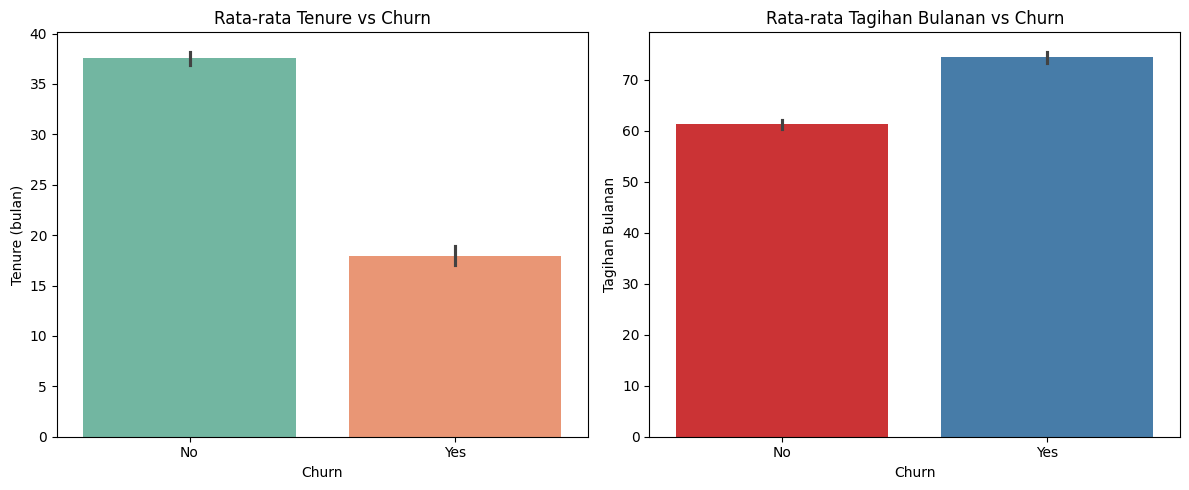

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

df.info()
display(df.describe())

# bandingkan tenure dan tagihan bulanan: churn vs tidak churn
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=df, x='Churn', y='tenure', hue='Churn', palette='Set2', legend=False, ax=ax[0])
ax[0].set_title('Rata-rata Tenure vs Churn')
ax[0].set_ylabel('Tenure (bulan)')

sns.barplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set1', legend=False, ax=ax[1])
ax[1].set_title('Rata-rata Tagihan Bulanan vs Churn')
ax[1].set_ylabel('Tagihan Bulanan')

plt.tight_layout()
plt.show()

**Hasil visualisasi:** pelanggan yang churn rata-rata **lama langganannya lebih pendek** dan **tagihan bulanannya lebih tinggi**.

**3 hipotesis awal:**
1. Pelanggan baru (tenure pendek) lebih rawan churn daripada pelanggan lama.
2. Makin tinggi tagihan bulanan, makin besar kemungkinan churn.
3. Pelanggan kontrak 1 atau 2 tahun lebih kecil kemungkinan churn daripada kontrak bulanan. *(masih dugaan, belum diuji lewat visualisasi)*

---

### 2b & 2c. Validasi dan Pembersihan Data

| Temuan | Penanganan | Alasan |
|---|---|---|
| `TotalCharges` terbaca teks karena ada spasi kosong (pelanggan baru, tenure = 0) | spasi diubah jadi NaN, tipe diubah ke angka, lalu 11 baris NaN dihapus | jumlahnya sangat sedikit, lebih aman dihapus daripada ditebak (imputasi) |
| Data duplikat | dihapus (22 baris) | biar data konsisten dan tidak terhitung dua kali |
| `customerID` | dibuang | cuma ID unik, tidak punya pola prediktif |

**Hasil:** 7.043 baris → **7.010 baris** (33 baris dihapus), 21 kolom → 20 kolom.

In [3]:
import numpy as np

shape_awal = df.shape

# customerID tidak dipakai (cuma ID)
df_clean = df.drop('customerID', axis=1)

# TotalCharges ada yang berisi spasi -> jadikan NaN, lalu ubah ke angka
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'].replace(' ', np.nan))

# hapus missing value dan duplikat
df_clean = df_clean.dropna()
df_clean = df_clean.drop_duplicates()

print("Ukuran sebelum:", shape_awal)
print("Ukuran sesudah:", df_clean.shape)
print("Baris dihapus:", shape_awal[0] - df_clean.shape[0])

Ukuran sebelum: (7043, 21)
Ukuran sesudah: (7010, 20)
Baris dihapus: 33


### 2d. Konstruksi Data
1. **Target encoding:** `Churn` Yes/No diubah jadi 1/0.
2. **One-hot encoding:** fitur kategorikal (Contract, InternetService, dll.) diubah jadi kolom biner (`drop_first=True` supaya tidak ada kolom yang redundan).
3. **Standardisasi:** `tenure`, `MonthlyCharges`, `TotalCharges` skalanya beda jauh, jadi disamakan (rata-rata 0, standar deviasi 1) supaya model, terutama Logistic Regression, tidak berat sebelah ke angka yang besar.

Tidak dibuat fitur baru (*feature engineering*), karena fitur yang ada sudah cukup menjawab tujuan analitik.

### 2e. Dokumentasi Hasil
| | Sebelum | Sesudah |
|---|---|---|
| Ukuran | 7.043 baris × 21 kolom | 7.010 baris × 31 kolom (30 fitur + 1 target) |
| Kondisi | `TotalCharges` berupa teks, ada missing dan duplikat | semua fitur numerik/biner, tanpa missing |

Hasil akhir (*analytical dataset*) disimpan ke **`analytical_dataset.csv`** dan dipakai di tahap pemodelan.

In [4]:
from sklearn.preprocessing import StandardScaler

# target: Yes/No -> 1/0
df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

# one-hot encoding untuk fitur kategorikal
df_encoded = pd.get_dummies(df_clean, drop_first=True)

# standardisasi kolom numerik
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])

# simpan analytical dataset
df_encoded.to_csv('analytical_dataset.csv', index=False)

print("Ukuran dataset akhir:", df_encoded.shape)
display(df_encoded.head(3))

Ukuran dataset akhir: (7010, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,-1.285566,-1.165523,-0.997284,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,0.060346,-0.264071,-0.176848,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,-1.244781,-0.367189,-0.962740,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True


## SOAL 03: Merancang Skenario Model dan Pengujian

### 3a & 3b. Asumsi dan Teknik Pemodelan
Tujuannya memprediksi churn (1) atau tidak (0), jadi ini **klasifikasi (supervised learning)**.

**Asumsi data:**
* Data sudah bersih, tanpa missing, dan semua fitur sudah numerik.
* Kelas target tidak seimbang (±74% vs ±26%).

**Teknik yang dipilih:**
* **Random Forest (model utama):** tahan terhadap outlier dan bisa menangkap pola non-linear antar fitur.
* **Logistic Regression (baseline / pembanding):** sederhana, cepat, dan bobot fiturnya mudah diinterpretasi.

### 3c. Skenario Pengujian
**Percentage splitting 80:20** (80% latih, 20% uji). Datanya cukup besar (±7.000 baris), jadi 80% sudah cukup buat belajar dan 20% cukup buat menguji. Pakai `stratify=y` supaya proporsi churn (±26%) sama di data latih dan data uji.

### 3d. Metrik dan Kriteria Keberhasilan
Salah menebak pelanggan yang mau pergi sebagai "aman" (*False Negative*) lebih merugikan daripada sebaliknya. Maka:
* **Metrik utama:** Recall dan F1-Score kelas Churn. Accuracy tetap dihitung sebagai gambaran umum.
* **Kriteria berhasil:** **Accuracy > 75%** dan **F1-Score kelas Churn > 0.55**.

In [5]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# split 80:20, stratify supaya proporsi churn sama di train dan test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Total data :", X.shape[0])
print("Data latih :", X_train.shape[0])
print("Data uji   :", X_test.shape[0])

Total data : 7010
Data latih : 5608
Data uji   : 1402


## SOAL 04: Membangun dan Menguji Model

### 4a & 4b. Parameter dan Eksekusi Baseline
Baseline: **Logistic Regression** dengan parameter default, hanya ditambah `max_iter=1000` supaya model konvergen dan `random_state=42` supaya hasil konsisten. Dilatih pakai data latih (`X_train`, `y_train`).

### 4c. Optimasi Hyperparameter
Model utama **Random Forest** dioptimasi pakai **GridSearchCV**:

| Parameter | Nilai yang diuji |
|---|---|
| `n_estimators` (jumlah pohon) | 50, 100 |
| `max_depth` (kedalaman pohon) | 5, 10 |

Pakai `cv=3` di data latih, dengan `scoring='f1'` supaya pencarian fokus ke kemampuan mendeteksi churn. Ambang keberhasilan mengikuti Soal 03 (Accuracy > 75%, F1 > 0.55).

**Parameter terbaik:** `max_depth=10`, `n_estimators=50`. Perbandingan hasil baseline vs optimasi ada di Soal 05.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# baseline: Logistic Regression (parameter default)
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train, y_train)

# Random Forest + Grid Search
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10]
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42),
                           param_grid, cv=3, scoring='f1')
grid_search.fit(X_train, y_train)

best_rf_model = grid_search.best_estimator_

print("Baseline selesai dilatih")
print("Parameter terbaik Random Forest:", grid_search.best_params_)

Baseline selesai dilatih
Parameter terbaik Random Forest: {'max_depth': 10, 'n_estimators': 50}


## SOAL 05: Mengevaluasi dan Melakukan Review Pemodelan

### 5a & 5b. Uji pada Data Baru dan Penilaian Hasil
Kedua model diuji pakai **data uji (`X_test`)** yang tidak dipakai saat training maupun tuning. Hasilnya (kelas Churn = 1):

| Model | Accuracy | Precision | Recall | F1-Score | Lolos kriteria? |
|---|---|---|---|---|---|
| Logistic Regression (baseline) | 0.8074 | 0.67 | 0.54 | 0.60 | Ya |
| Random Forest (optimasi) | 0.8010 | 0.66 | 0.51 | 0.57 | Ya |

Confusion matrix di bawah menunjukkan berapa pelanggan churn yang berhasil dan gagal terdeteksi.

Logistic Regression (Baseline)
Accuracy: 0.8074
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1031
           1       0.67      0.54      0.60       371

    accuracy                           0.81      1402
   macro avg       0.76      0.72      0.73      1402
weighted avg       0.80      0.81      0.80      1402

Random Forest (Optimasi)
Accuracy: 0.8010
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1031
           1       0.66      0.51      0.57       371

    accuracy                           0.80      1402
   macro avg       0.75      0.71      0.72      1402
weighted avg       0.79      0.80      0.79      1402



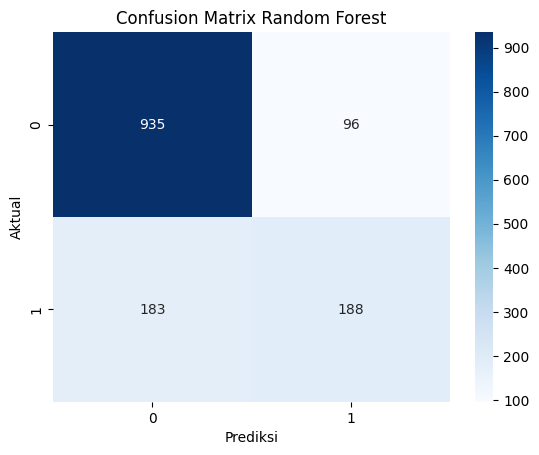

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# prediksi pakai data uji
y_pred_base = baseline_model.predict(X_test)
y_pred_rf = best_rf_model.predict(X_test)

print("Logistic Regression (Baseline)")
print(f"Accuracy: {accuracy_score(y_test, y_pred_base):.4f}")
print(classification_report(y_test, y_pred_base))

print("Random Forest (Optimasi)")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(classification_report(y_test, y_pred_rf))

# confusion matrix Random Forest
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix Random Forest')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

### 5c. Review Proses dan Rekomendasi

**Kesesuaian dengan rencana:** semua tahap sesuai skenario Soal 03: split 80:20 dengan stratifikasi, metrik Accuracy/Precision/Recall/F1, dan GridSearch hanya memakai data latih sehingga data uji benar-benar "baru".

**Hasil:** kedua model lolos kriteria (Accuracy ±80% > 75%, F1 0.57 sampai 0.60 > 0.55). Yang menarik, **Logistic Regression yang sederhana justru sedikit lebih unggul** daripada Random Forest hasil tuning di semua metrik.

**Keterbatasan:**
* Recall churn cuma ±51-54%, artinya hampir separuh pelanggan yang akan pergi masih lolos dari deteksi. Penyebabnya data tidak seimbang, jadi model lebih jago menebak pelanggan yang bertahan.
* Grid search-nya kecil (2 parameter × 2 nilai), jadi masih ada ruang untuk dieksplor.

**Rekomendasi:**
* **Teknis:** coba penyeimbangan data (SMOTE atau `class_weight`), turunkan threshold prediksi, dan perluas grid search.
* **Bisnis:** Tim Marketing bisa mulai pakai model (Logistic Regression, karena sedikit lebih baik dan mudah dijelaskan) untuk bikin daftar pelanggan berisiko churn dan memberi promo retensi ke mereka. Target turun 5% sebaiknya dibuktikan lewat uji coba kampanye dulu.